# 03 — Day-ahead forecasting models

**Task:** at the end of day D-1, forecast all 24 hourly values of Ontario demand for day D.

**Split:** train 2019–2023 · validate/tune 2024 · **test 2025** (untouched until the end) · final models refit on 2019–2024.

**Models:** persistence baselines (from notebook 02) → Ridge regression with calendar + weather terms → LightGBM gradient boosting.

**Assumption to keep in mind:** weather features use *observed* Toronto weather for day D as a stand-in for a day-ahead weather forecast. Real operational accuracy would be somewhat worse because weather forecasts have their own error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from src.data import build_dataset
from src.features import make_features, FEATURES

d = make_features(build_dataset())
train, valid, test = d.loc[:"2023"], d.loc["2024"], d.loc["2025"]
train_full = d.loc[:"2024"]
print(len(train), len(valid), len(test))

43656 8784 8760


In [2]:
def metrics(y, yhat):
    err = yhat - y
    return pd.Series({"MAE (MW)": err.abs().mean(),
                      "RMSE (MW)": np.sqrt((err ** 2).mean()),
                      "MAPE (%)": (err.abs() / y).mean() * 100})

def peak_metrics(y, yhat):
    # error on each day's peak hour value (what system planners care about most)
    dy, dp = y.resample("D").max(), pd.Series(yhat, index=y.index).resample("D").max()
    e = dp - dy
    return pd.Series({"Daily peak MAE (MW)": e.abs().mean(), "Daily peak MAPE (%)": (e.abs() / dy).mean() * 100})

## Ridge regression (calendar one-hot + weather + lags)

In [3]:
cat = ["hour", "dow", "month"]
num = [f for f in FEATURES if f not in cat]
ridge = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)]),
    Ridge(alpha=1.0),
)
ridge.fit(train[FEATURES], train["demand_mw"])
print("validation 2024:", metrics(valid["demand_mw"], ridge.predict(valid[FEATURES])).round(1).to_dict())

validation 2024: {'MAE (MW)': 549.9, 'RMSE (MW)': 702.0, 'MAPE (%)': 3.4}


## LightGBM — tuned with early stopping on 2024

In [4]:
params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)
gbm = lgb.LGBMRegressor(n_estimators=3000, **params)
gbm.fit(train[FEATURES], train["demand_mw"], eval_set=[(valid[FEATURES], valid["demand_mw"])],
        callbacks=[lgb.early_stopping(100, verbose=False)])
best_iter = gbm.best_iteration_
print("best iteration:", best_iter)
print("validation 2024:", metrics(valid["demand_mw"], gbm.predict(valid[FEATURES])).round(1).to_dict())

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best iteration: 866


validation 2024: {'MAE (MW)': 416.3, 'RMSE (MW)': 545.8, 'MAPE (%)': 2.5}


### Ablation: how much does weather add?
Same model, weather columns removed.

In [5]:
no_wx = [f for f in FEATURES if not any(k in f for k in ["temp", "hdd", "cdd", "rh_", "cloud"])]
gbm_nowx = lgb.LGBMRegressor(n_estimators=3000, **params)
gbm_nowx.fit(train[no_wx], train["demand_mw"], eval_set=[(valid[no_wx], valid["demand_mw"])],
             callbacks=[lgb.early_stopping(100, verbose=False)])
print("validation 2024, no weather:", metrics(valid["demand_mw"], gbm_nowx.predict(valid[no_wx])).round(1).to_dict())

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


validation 2024, no weather: {'MAE (MW)': 580.5, 'RMSE (MW)': 792.7, 'MAPE (%)': 3.6}


## Final test on 2025
Refit every model on 2019–2024 (fixed settings from validation), then score once on 2025.

In [6]:
y_test = test["demand_mw"]
ridge.fit(train_full[FEATURES], train_full["demand_mw"])
gbm_final = lgb.LGBMRegressor(n_estimators=int(best_iter * 1.1), **params).fit(train_full[FEATURES], train_full["demand_mw"])
gbm_nowx_final = lgb.LGBMRegressor(n_estimators=int(gbm_nowx.best_iteration_ * 1.1), **params).fit(train_full[no_wx], train_full["demand_mw"])

preds = {
    "Persistence (lag 24h)": test["lag_24"].values,
    "Weekly persistence (lag 168h)": test["lag_168"].values,
    "Ridge regression": ridge.predict(test[FEATURES]),
    "LightGBM, no weather": gbm_nowx_final.predict(test[no_wx]),
    "LightGBM, with weather": gbm_final.predict(test[FEATURES]),
}
results = pd.DataFrame({k: pd.concat([metrics(y_test, v), peak_metrics(y_test, v)]) for k, v in preds.items()}).T.round(1)
results.to_csv("results/test_2025_results.csv")
results

,MAE (MW),RMSE (MW),MAPE (%),Daily peak MAE (MW),Daily peak MAPE (%)
Persistence (lag 24h),758.0,1030.4,4.6,718.6,3.8
Weekly persistence (lag 168h),1197.0,1673.0,7.0,1265.2,6.6
Ridge regression,576.2,718.7,3.5,596.2,3.1
"LightGBM, no weather",638.4,875.5,3.7,763.8,3.9
"LightGBM, with weather",447.9,583.3,2.6,536.6,2.8


In [7]:
best = preds["LightGBM, with weather"]
base = preds["Persistence (lag 24h)"]
print(f"LightGBM cuts MAE by {(1 - results.loc['LightGBM, with weather','MAE (MW)'] / results.loc['Persistence (lag 24h)','MAE (MW)'])*100:.0f}% vs persistence")

LightGBM cuts MAE by 41% vs persistence


## Forecast vs actual — a winter week and a summer week

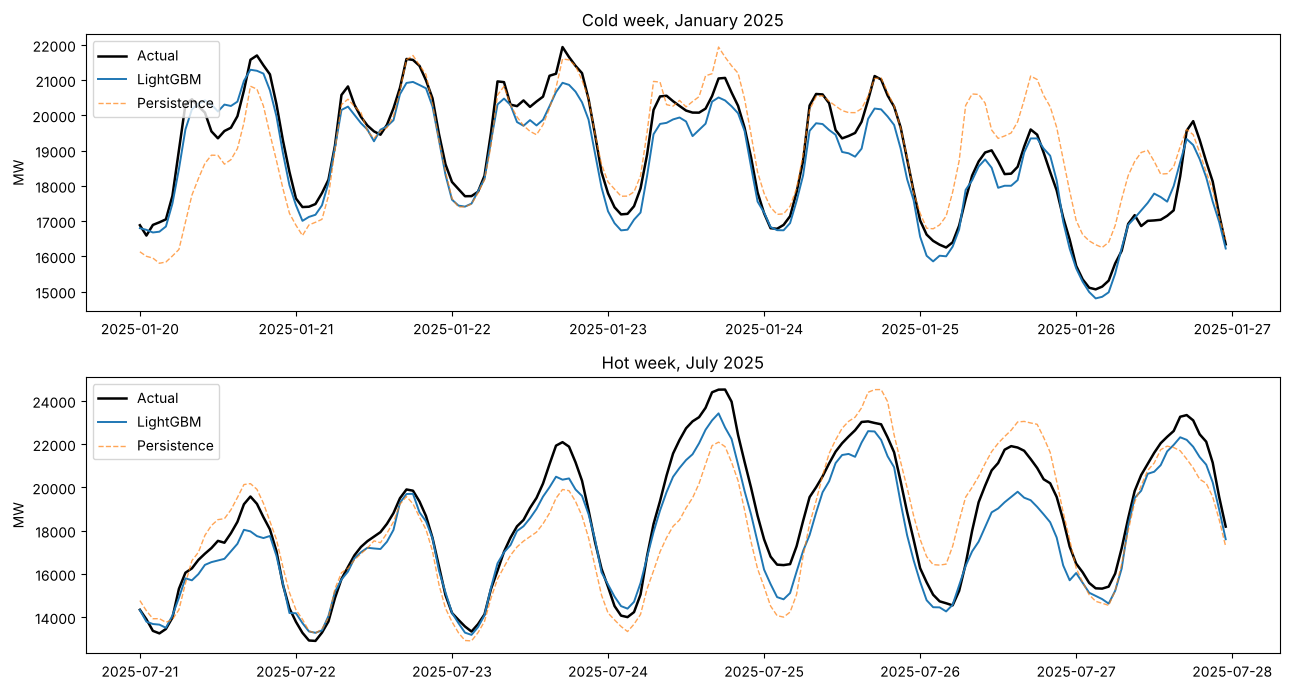

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, (start, end, title) in zip(axes, [("2025-01-20", "2025-01-26", "Cold week, January 2025"),
                                          ("2025-07-21", "2025-07-27", "Hot week, July 2025")]):
    sl = slice(start, end)
    ax.plot(y_test.loc[sl].index, y_test.loc[sl], label="Actual", color="black", lw=1.8)
    ax.plot(y_test.loc[sl].index, pd.Series(best, index=y_test.index).loc[sl], label="LightGBM", lw=1.4)
    ax.plot(y_test.loc[sl].index, pd.Series(base, index=y_test.index).loc[sl], label="Persistence", lw=1, alpha=0.7, ls="--")
    ax.set(title=title, ylabel="MW"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig("figures/forecast_weeks_2025.png", dpi=130)

## Where does the model struggle? Error by month

datetime,1,2,3,4,5,6,7,8,9,10,11,12
LightGBM,2.18,2.60,2.63,2.61,2.31,3.01,3.33,3.04,2.37,2.56,2.35,2.59
Persistence,3.84,2.95,4.99,5.44,4.35,7.22,6.11,4.17,4.28,3.95,3.58,3.97


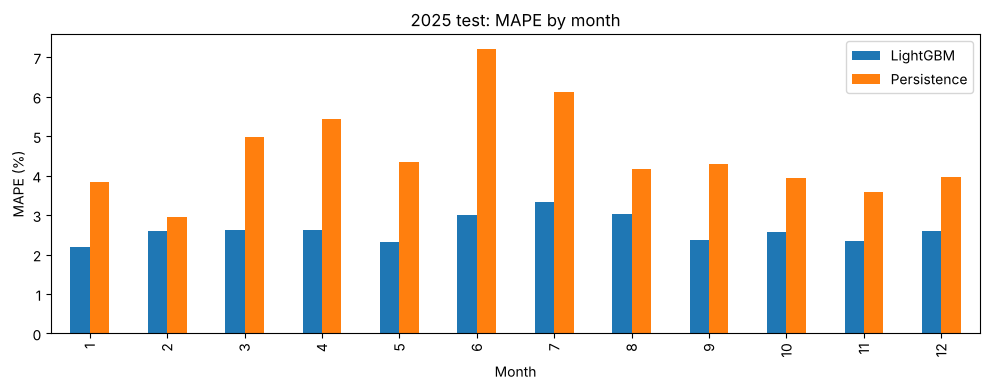

In [9]:
err = pd.DataFrame({"LightGBM": np.abs(best - y_test) / y_test * 100,
                    "Persistence": np.abs(base - y_test) / y_test * 100})
monthly = err.groupby(err.index.month).mean()
ax = monthly.plot(kind="bar", figsize=(10, 4), title="2025 test: MAPE by month", ylabel="MAPE (%)", xlabel="Month")
plt.tight_layout(); plt.savefig("figures/mape_by_month_2025.png", dpi=130)
monthly.round(2).T

## What drives the forecast? (LightGBM gain importance)

lag_24           67.0
lag_168          10.8
temp_c            4.8
dow               3.2
hour              2.6
prev_day_max      2.3
temp_day_mean     1.7
cdd               1.0
dtype: float64

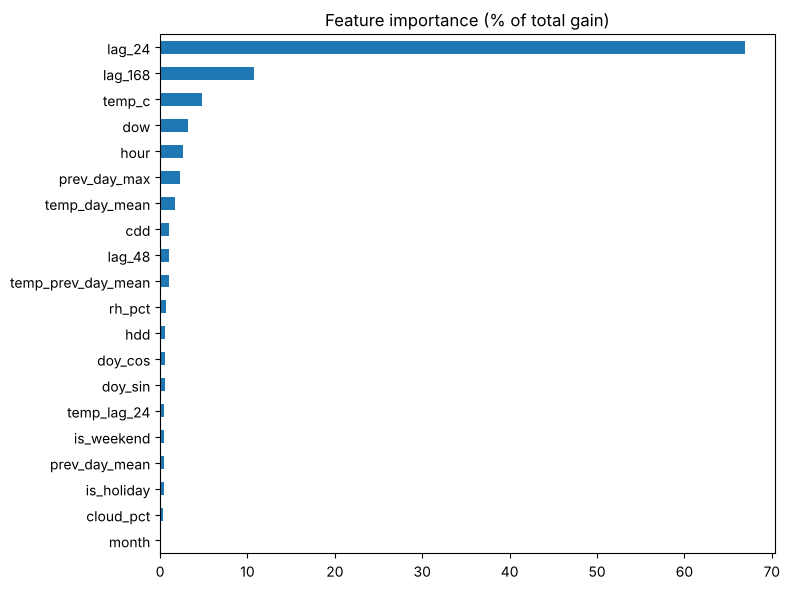

In [10]:
imp = pd.Series(gbm_final.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum() * 100).sort_values()
ax = imp.plot(kind="barh", figsize=(8, 6), title="Feature importance (% of total gain)")
plt.tight_layout(); plt.savefig("figures/feature_importance.png", dpi=130)
imp.sort_values(ascending=False).head(8).round(1)

## Takeaways (2025 test year)

- **LightGBM with weather: MAPE 2.6%, MAE 448 MW**, a 41% lower error than "same hour yesterday" (MAPE 4.6%). Daily peak error drops from 3.8% to 2.8%.
- **Weather matters most.** Without the weather features the same model scores 3.7% MAPE, and its daily-peak error is no better than the persistence baseline. Temperature is what lets the model anticipate cold snaps and heat waves.
- **Ridge regression (3.5%)** captures the calendar and heating/cooling effects but not their interactions (e.g. the evening peak responds to cold differently than the night).
- **Summer is hardest.** Errors are highest in June–July (about 3.0–3.3% MAPE). On the hottest days the model *under-forecasts* the afternoon peak (see 24 July 2025 above), because cooling load rises steeply above ~25 °C and such days are rare in the training data.
- 2025 demand was ~4% higher than 2024 on average; because the model leans on recent lags it adapts to this load growth, while purely calendar-based models would drift.

**Next steps:** use archived *forecast* weather instead of observed weather (realistic operations); population-weighted temperature across Ontario cities; humidex/heat-index features for summer peaks; quantile forecasts for peak risk; SARIMAX and LSTM comparisons.